In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [2]:
d1 = find_file("240510_TS_C10_W3S2_run3.DSC", exp_type="francklab_esr/romana") # cooling 1 --initial sample
d2 = find_file("240510_TS_C10_W3S2_run4.DSC", exp_type="francklab_esr/romana") # heating 2 subsequently --after cooling and heating

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 3$ in Dodecane for cooling2')

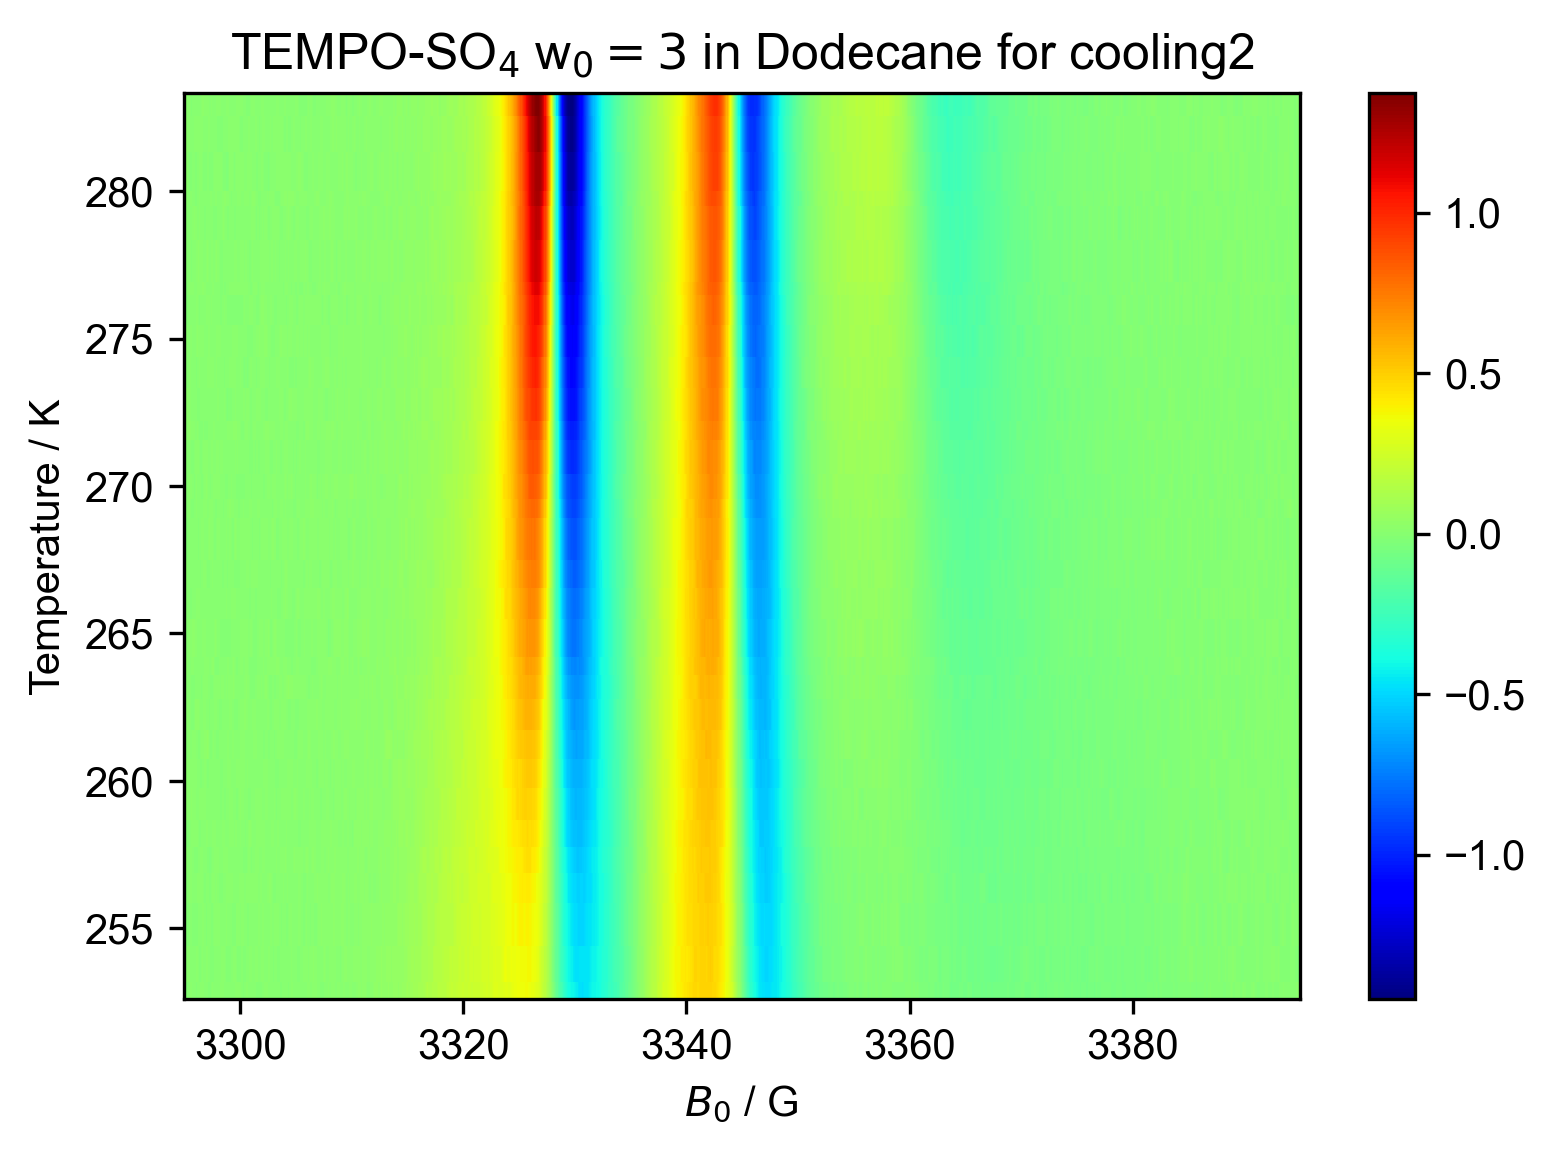

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 3$ in Dodecane for cooling2")

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 3$ in Dodecane for heating2')

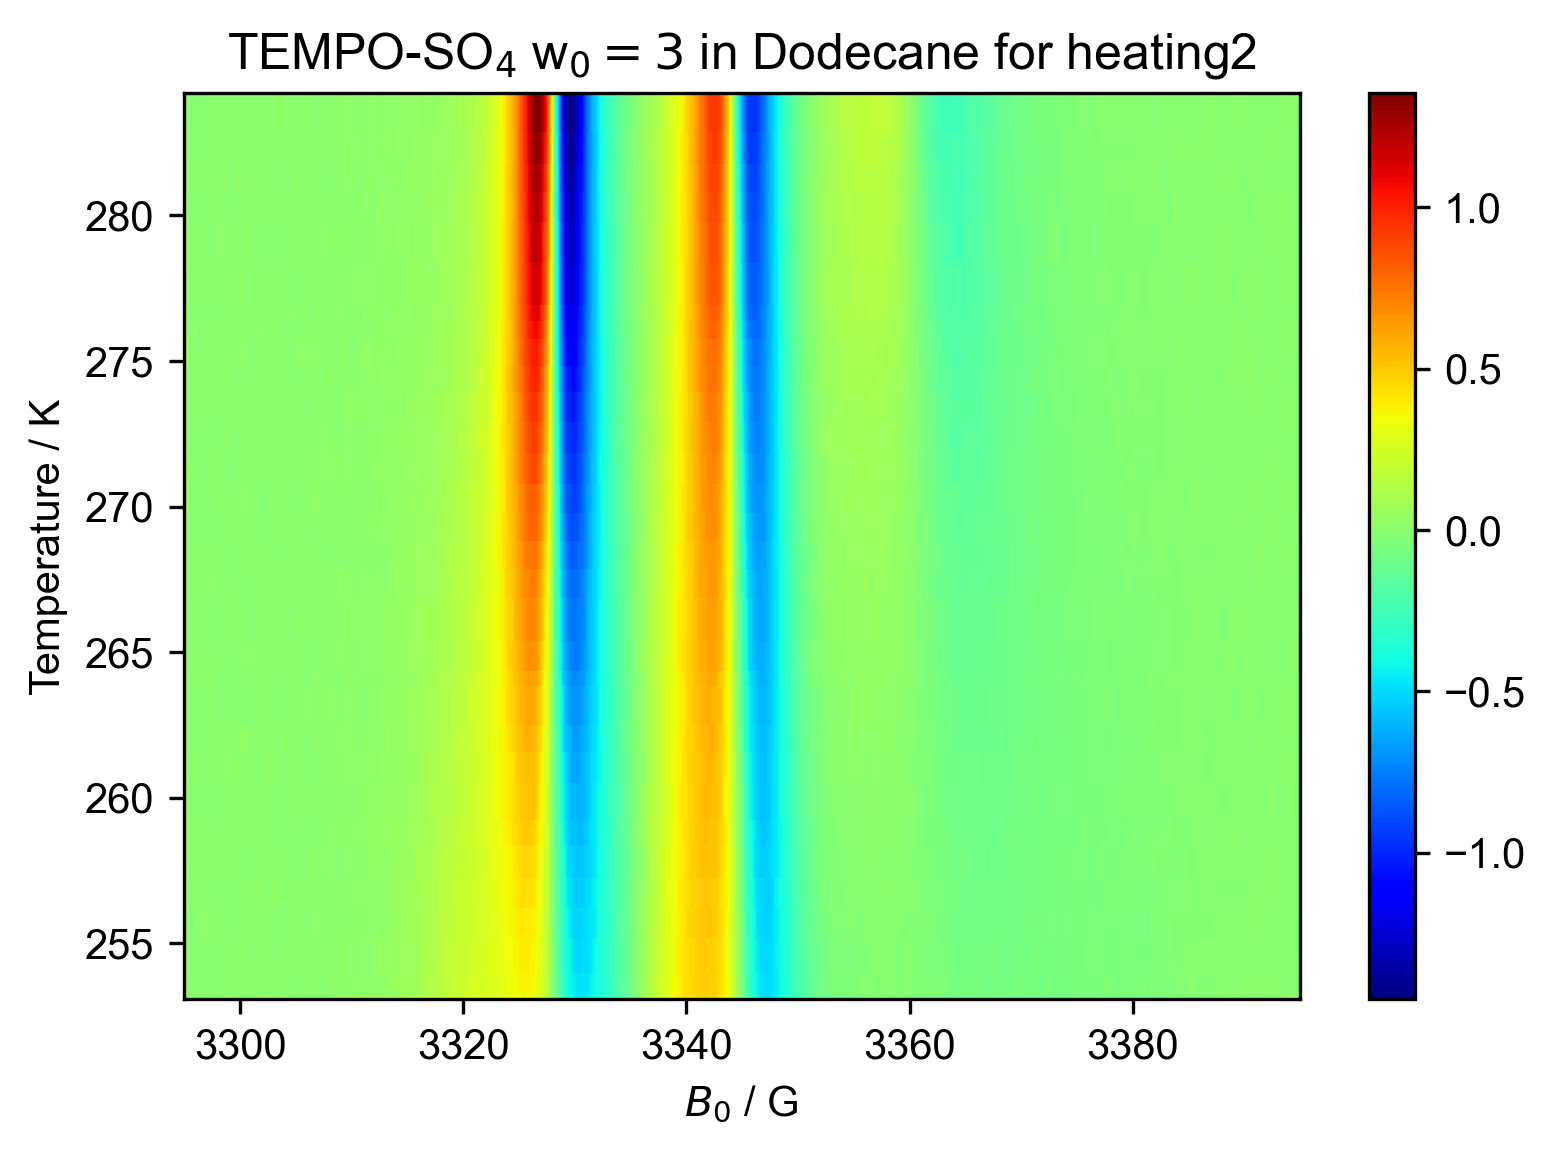

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 3$ in Dodecane for heating2")

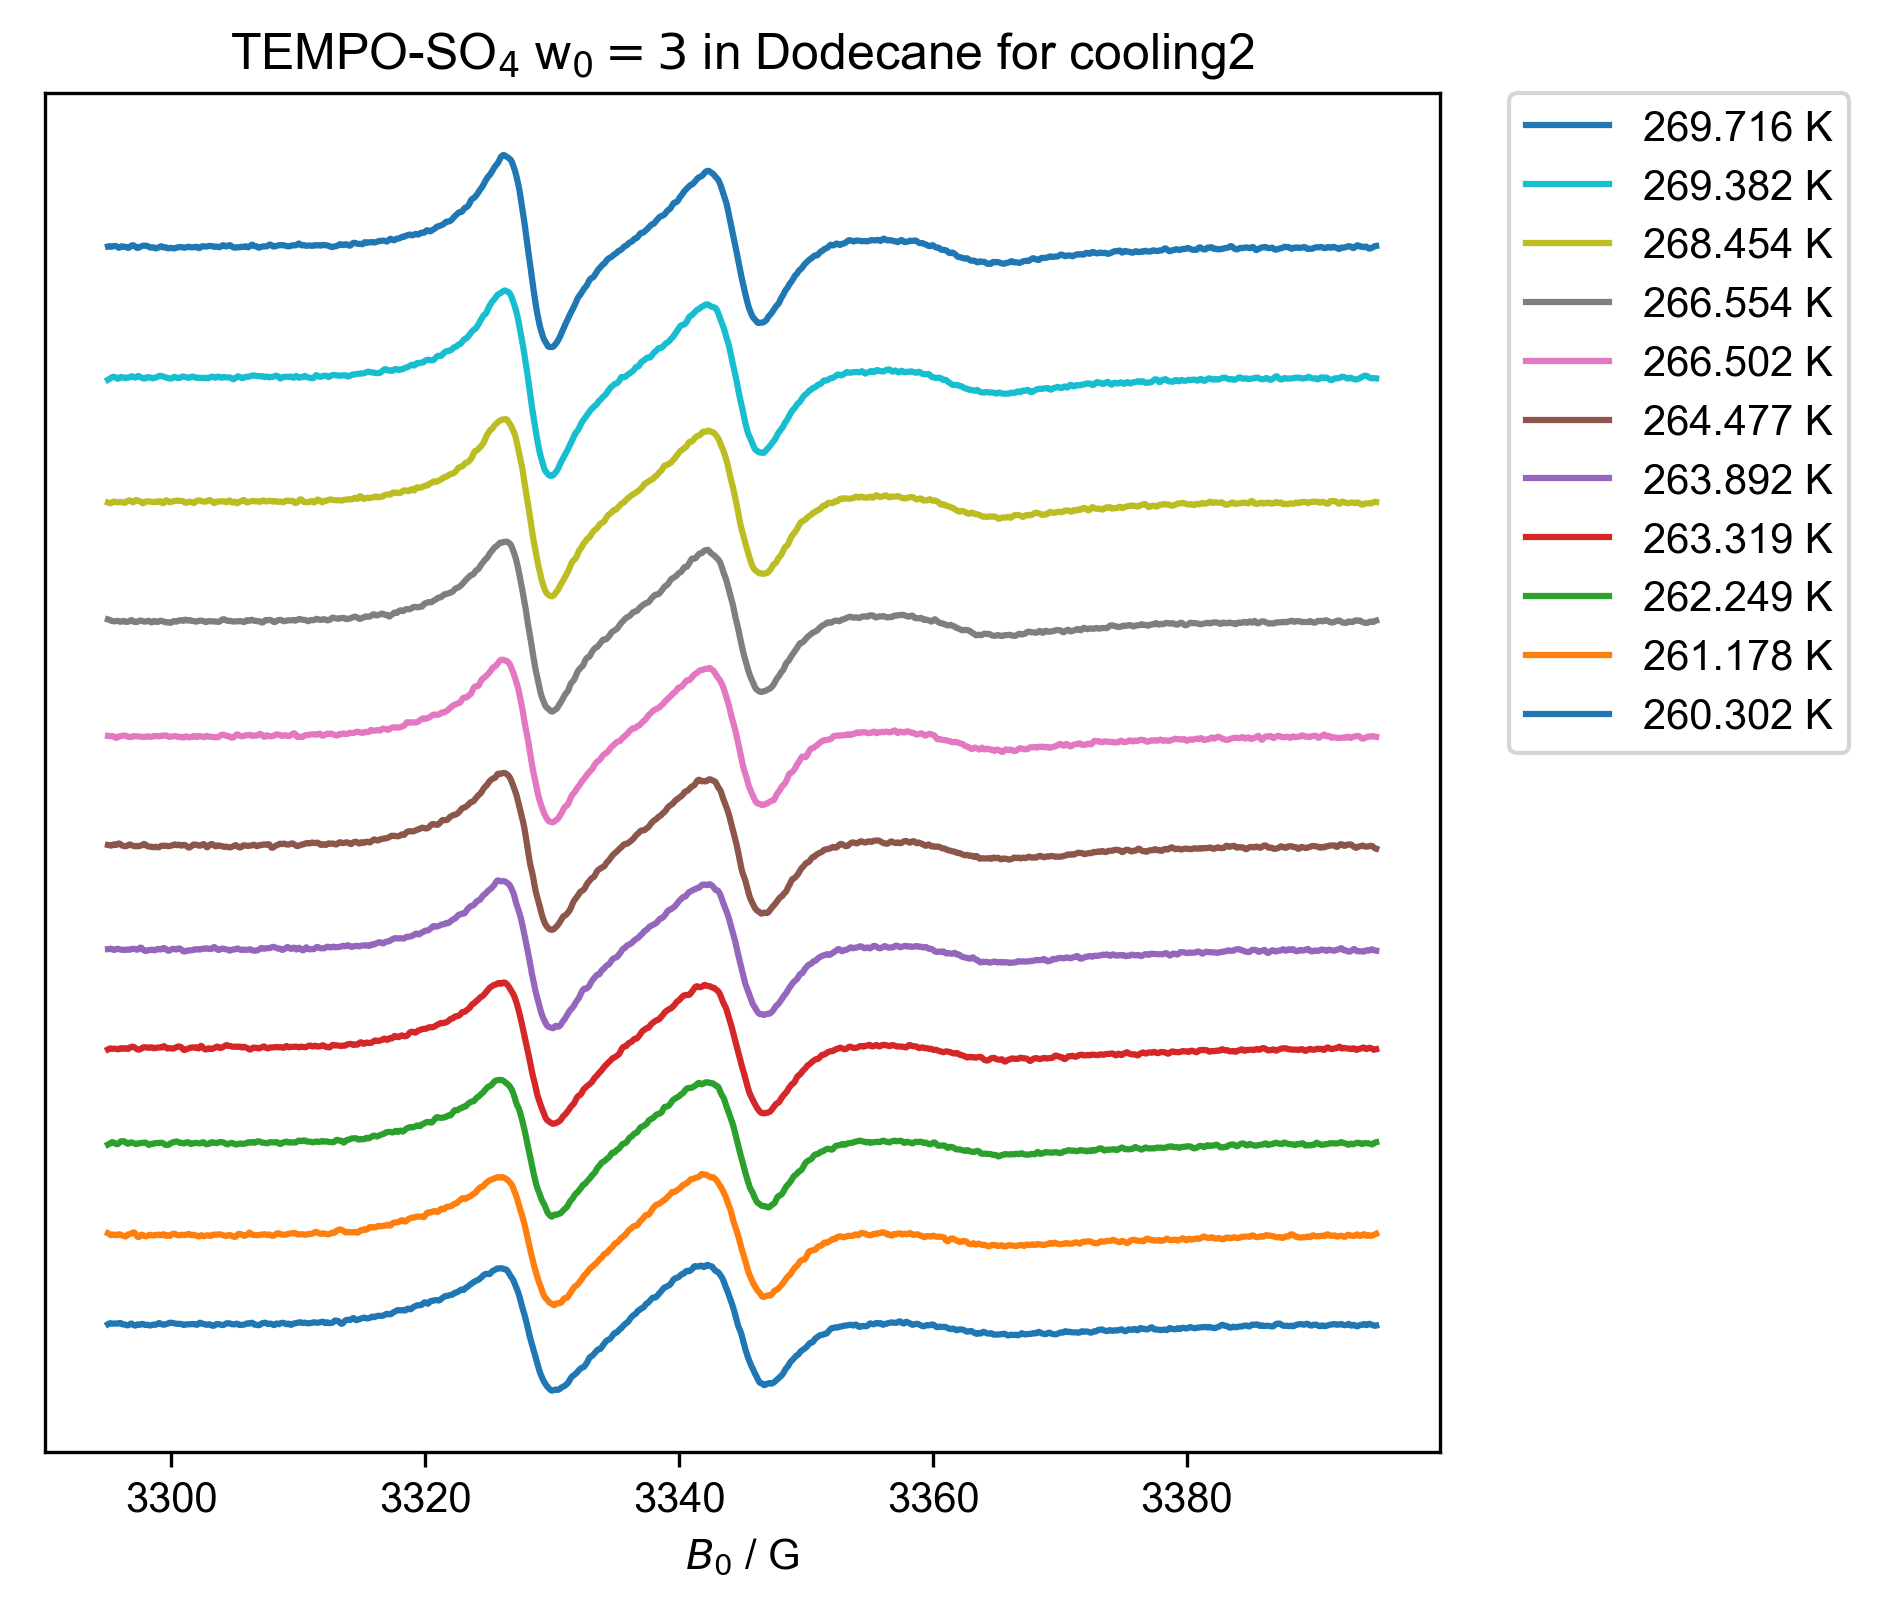

In [18]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 3$ in Dodecane for cooling2", (260, 270))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

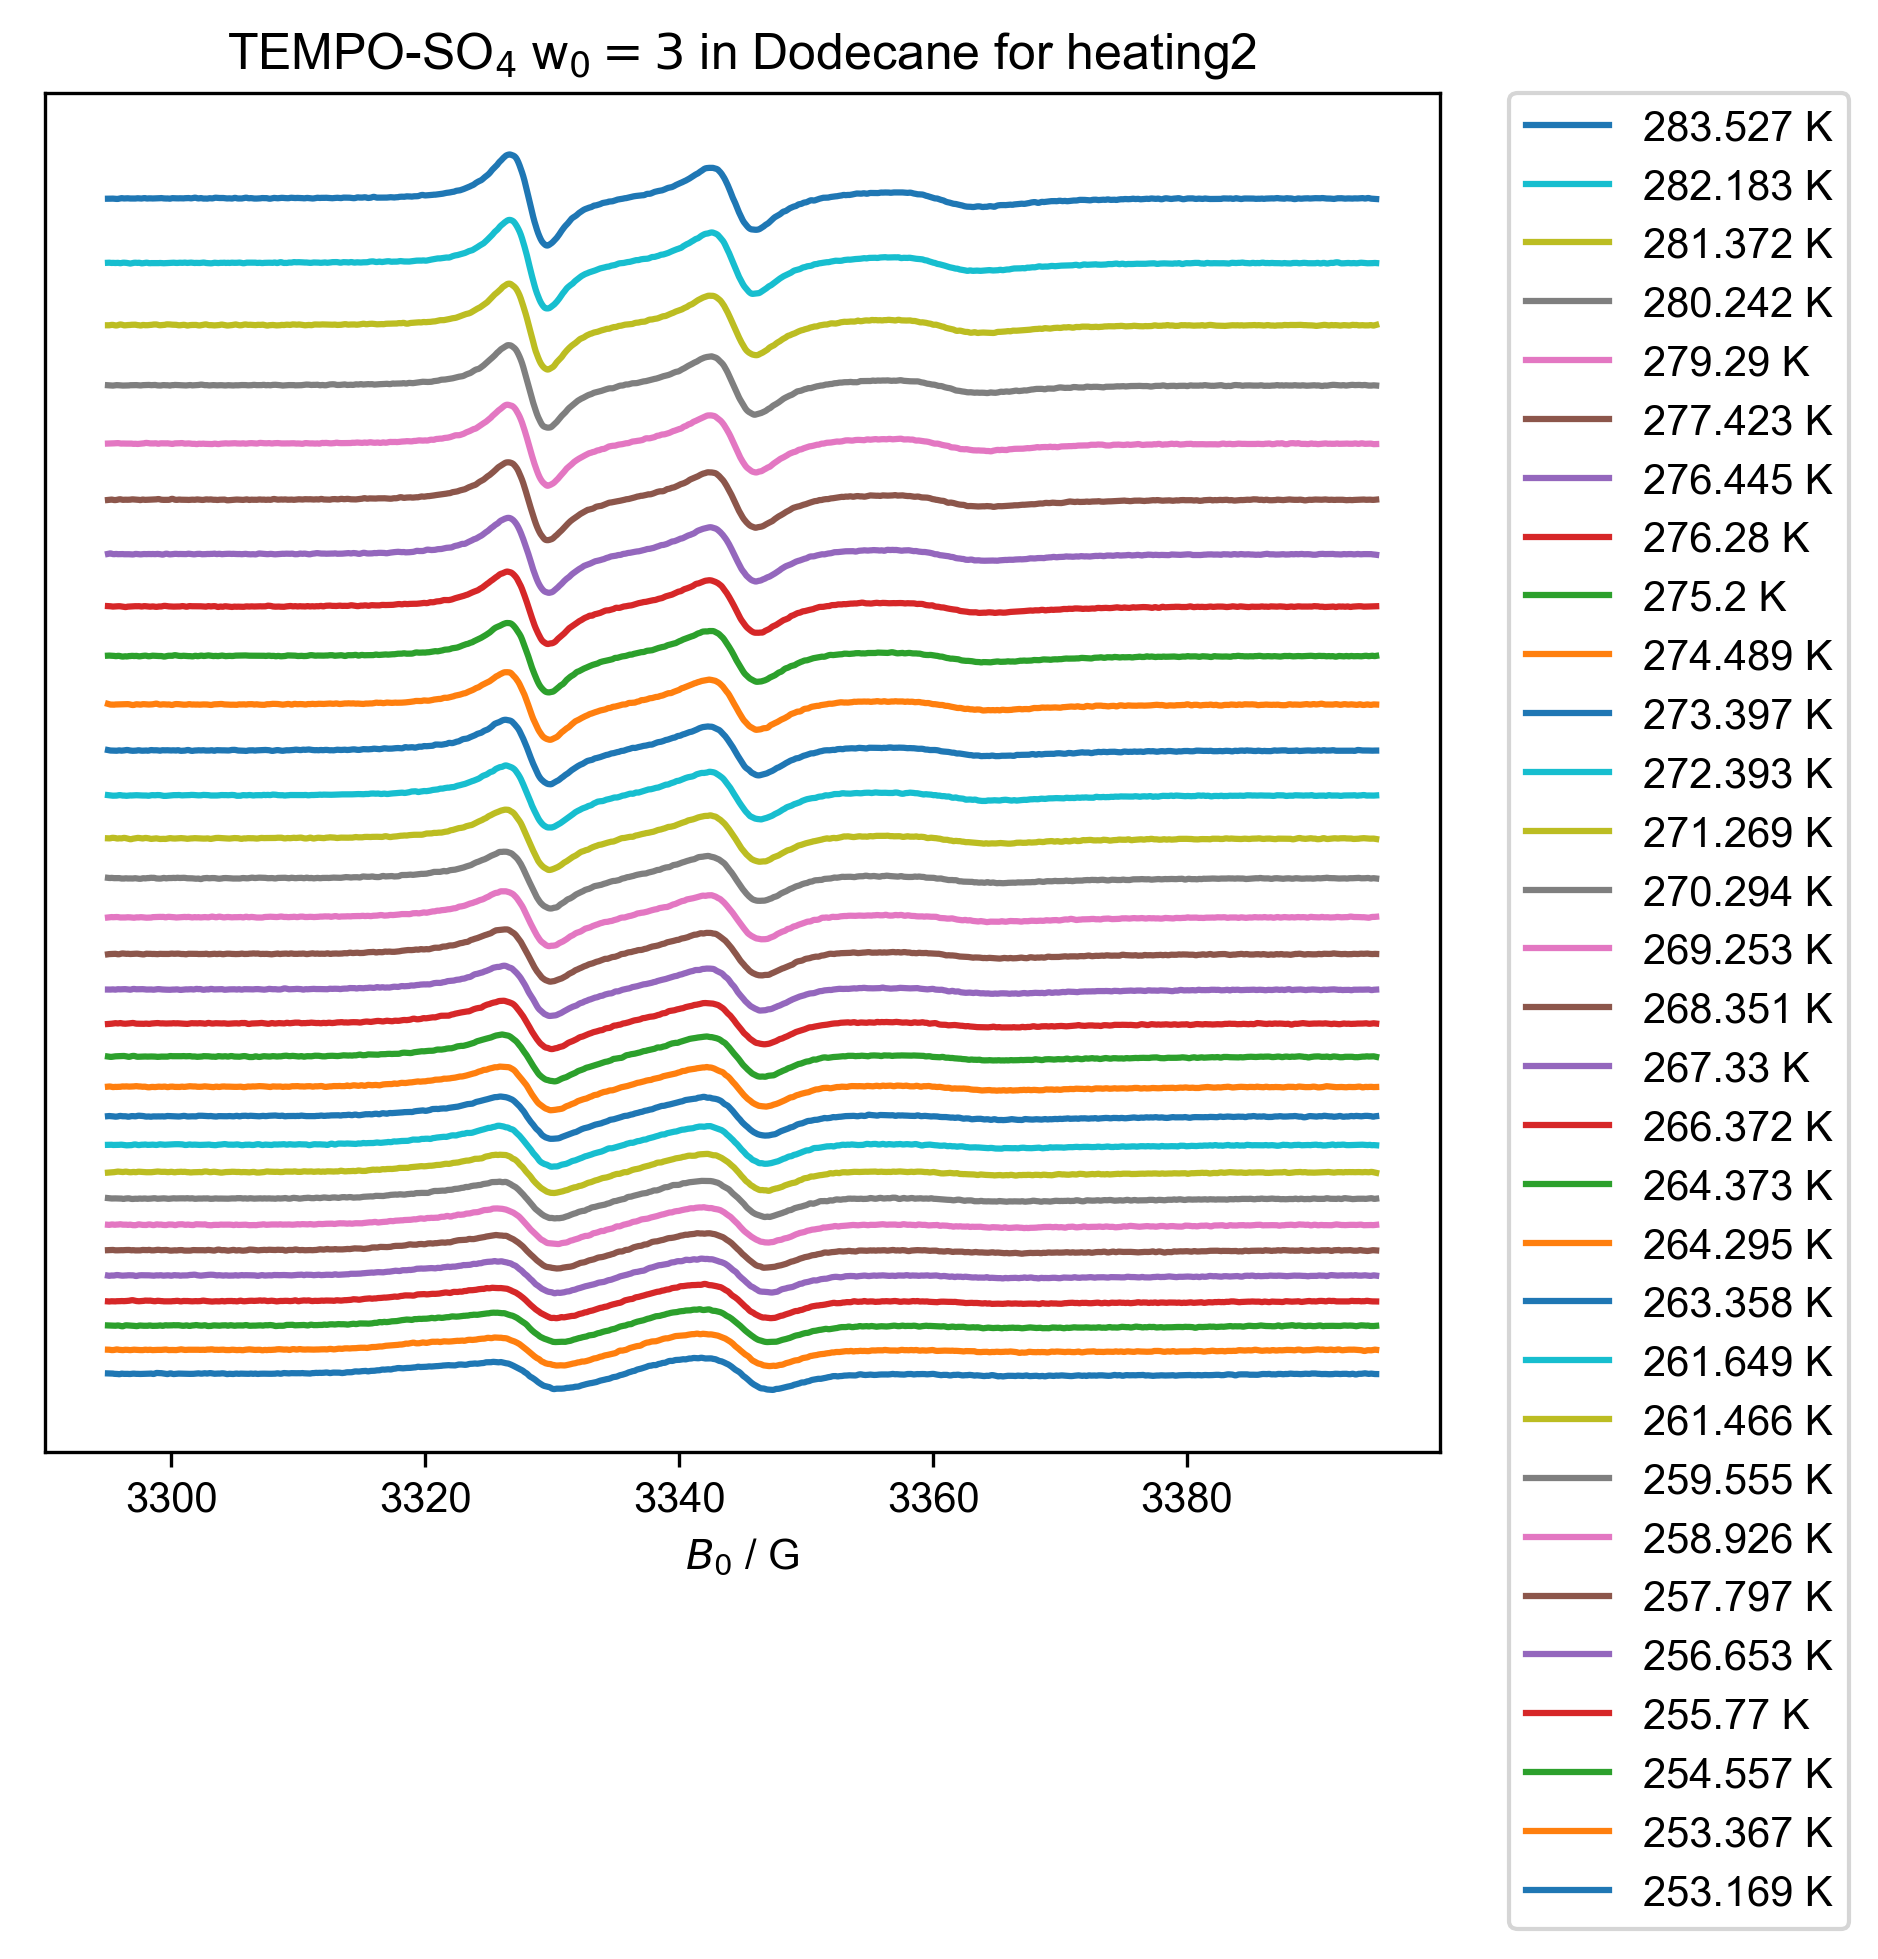

In [10]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0=3$ in Dodecane for heating2", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

[252.878 253.46  255.296 256.403 257.35  258.125 259.201 260.302 261.178
 262.249 263.319 263.892 264.477 266.502 266.554 268.454 269.382 269.716
 271.077 272.036 272.38  274.273 274.514 276.382 276.56  277.284 279.417
 279.557 280.496 282.145 282.932]
[253.169 253.367 254.557 255.77  256.653 257.797 258.926 259.555 261.466
 261.649 263.358 264.295 264.373 266.372 267.33  268.351 269.253 270.294
 271.269 272.393 273.397 274.489 275.2   276.28  276.445 277.423 279.29
 280.242 281.372 282.183 283.527]


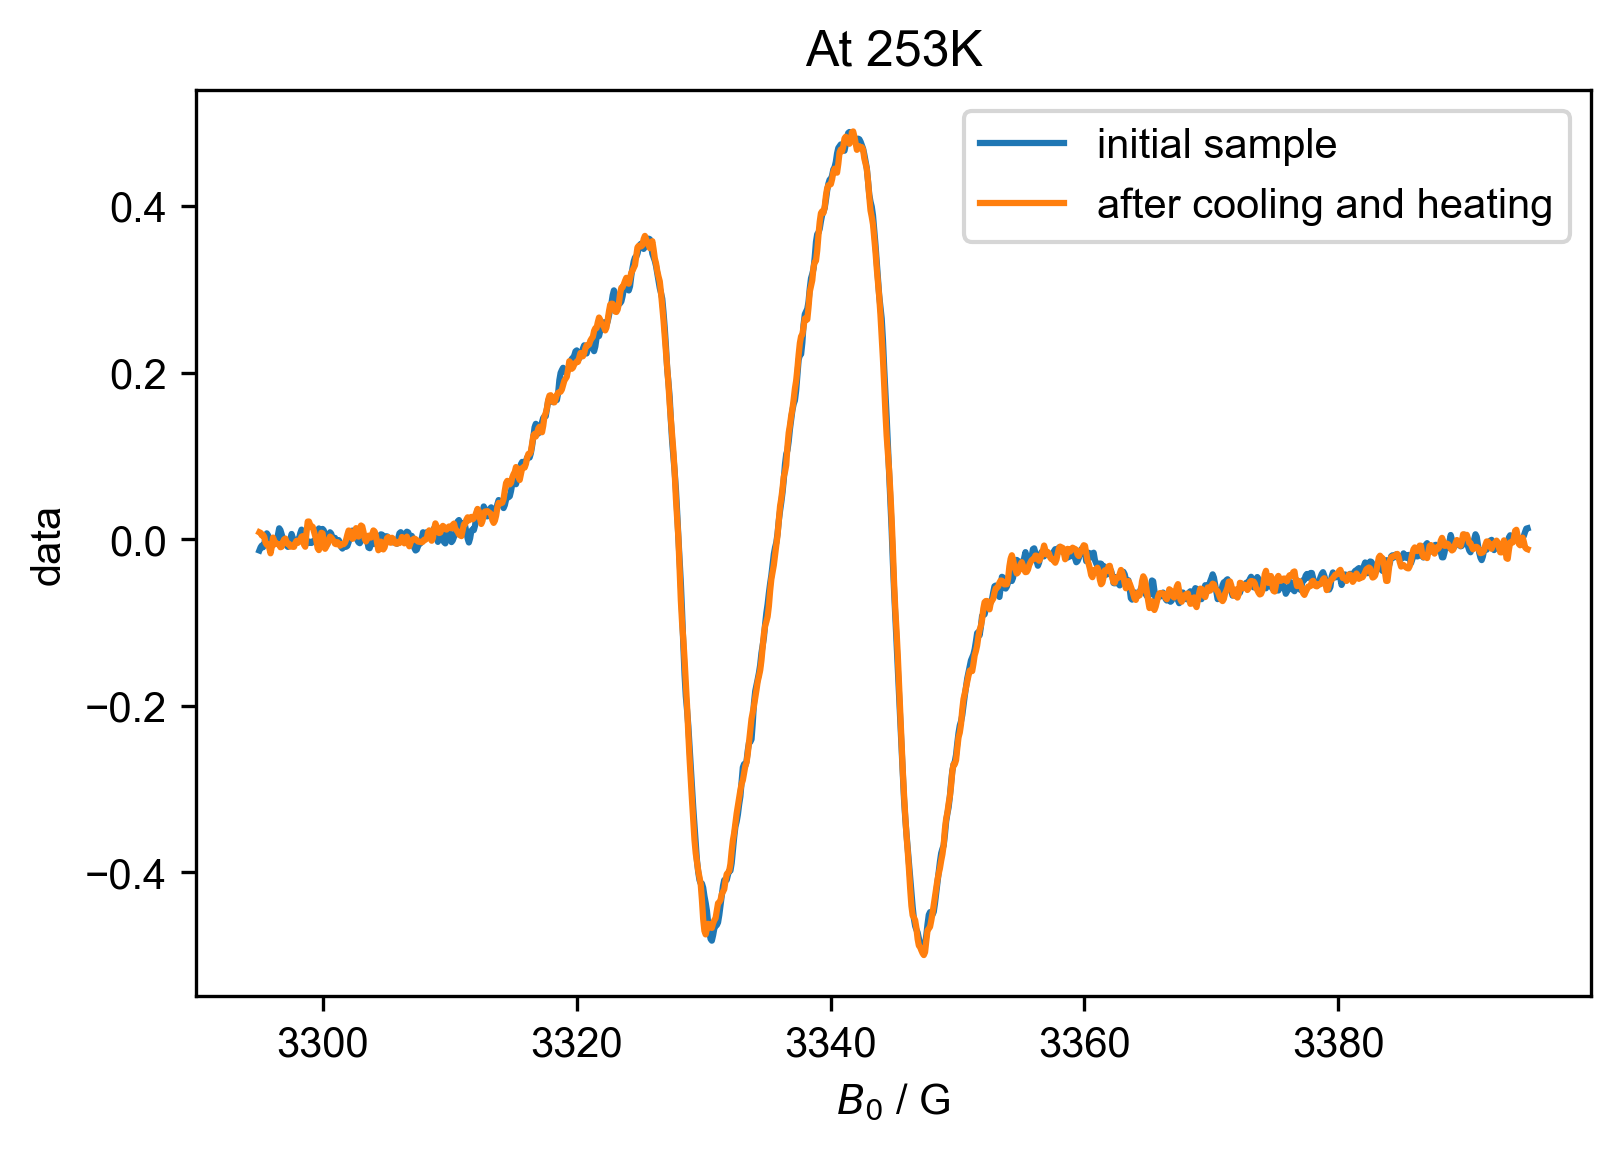

In [11]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":253], label="initial sample")
plot(d2["Temperature":253], label="after cooling and heating")
title("At 253K")
legend()

[252.878 253.46  255.296 256.403 257.35  258.125 259.201 260.302 261.178
 262.249 263.319 263.892 264.477 266.502 266.554 268.454 269.382 269.716
 271.077 272.036 272.38  274.273 274.514 276.382 276.56  277.284 279.417
 279.557 280.496 282.145 282.932]
[253.169 253.367 254.557 255.77  256.653 257.797 258.926 259.555 261.466
 261.649 263.358 264.295 264.373 266.372 267.33  268.351 269.253 270.294
 271.269 272.393 273.397 274.489 275.2   276.28  276.445 277.423 279.29
 280.242 281.372 282.183 283.527]


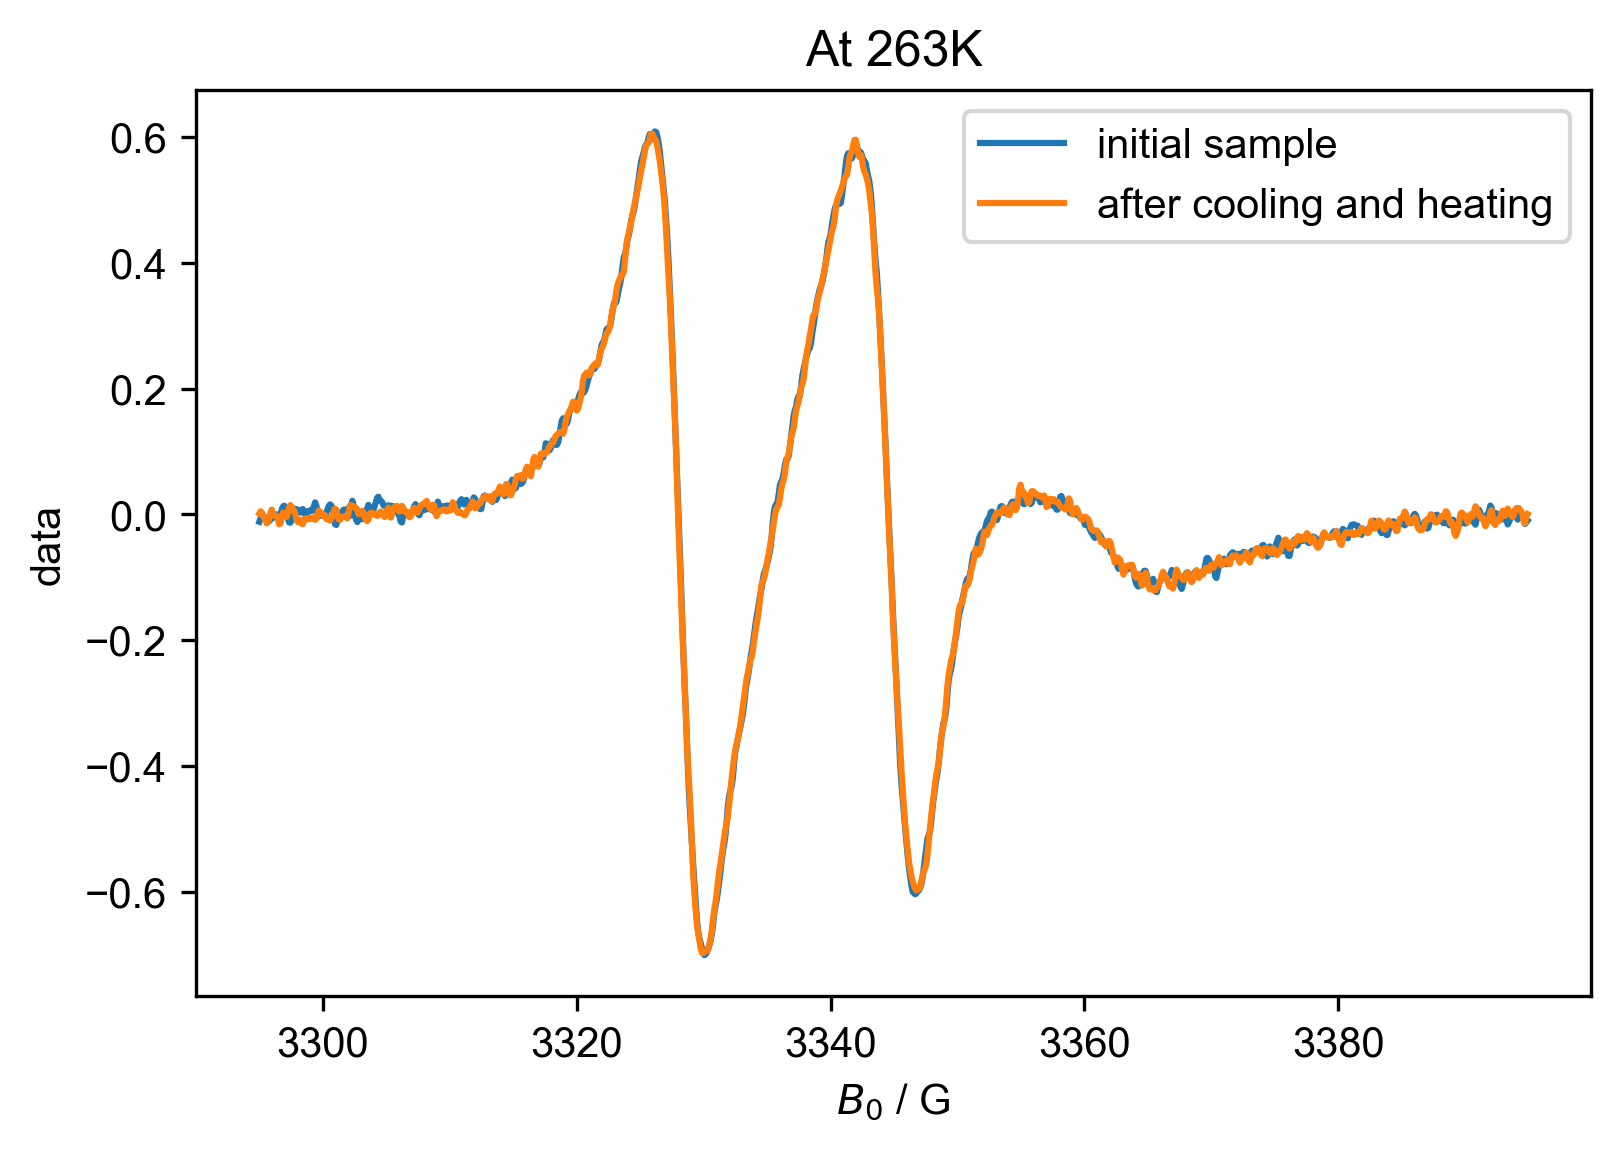

In [12]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":263], label="initial sample")
plot(d2["Temperature":263], label="after cooling and heating")
title("At 263K")
legend()

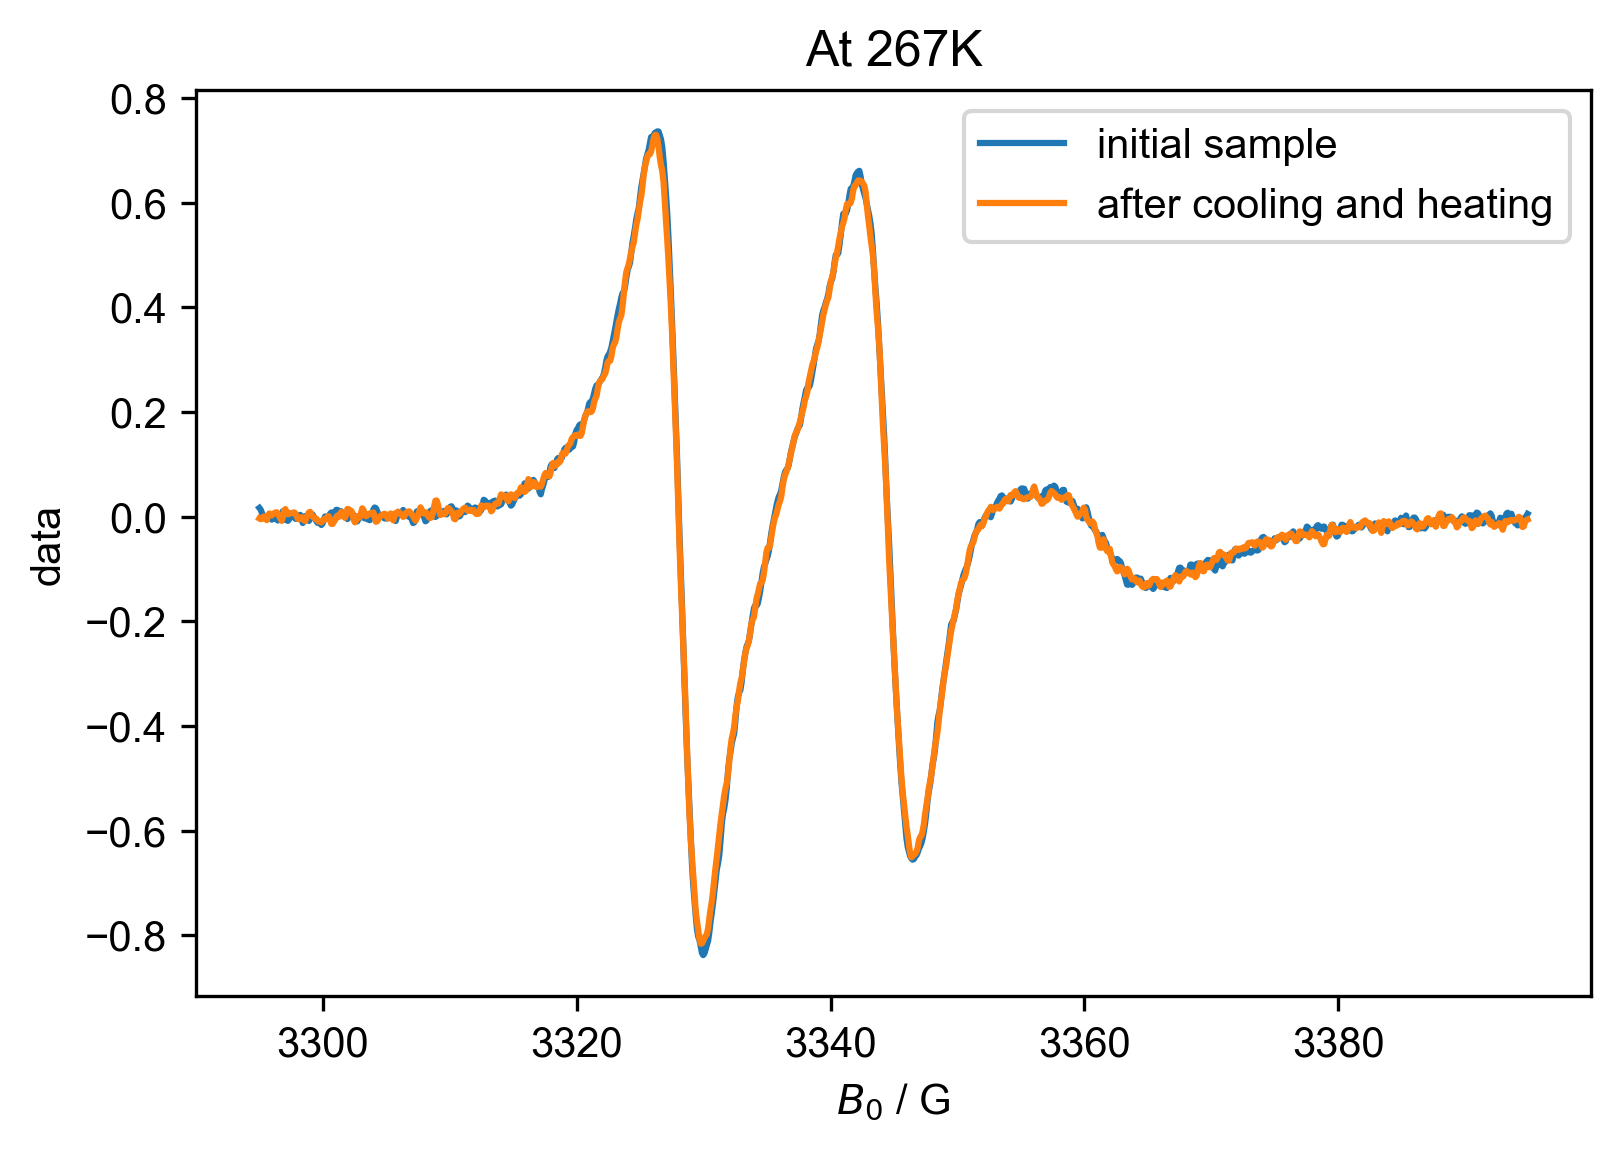

In [13]:
#near room temperature
# print(d1.getaxis("Temperature"))
# print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":267], label="initial sample")
plot(d2["Temperature":267], label="after cooling and heating")
title("At 267K")
legend()

[252.878 253.46  255.296 256.403 257.35  258.125 259.201 260.302 261.178
 262.249 263.319 263.892 264.477 266.502 266.554 268.454 269.382 269.716
 271.077 272.036 272.38  274.273 274.514 276.382 276.56  277.284 279.417
 279.557 280.496 282.145 282.932]
[253.169 253.367 254.557 255.77  256.653 257.797 258.926 259.555 261.466
 261.649 263.358 264.295 264.373 266.372 267.33  268.351 269.253 270.294
 271.269 272.393 273.397 274.489 275.2   276.28  276.445 277.423 279.29
 280.242 281.372 282.183 283.527]


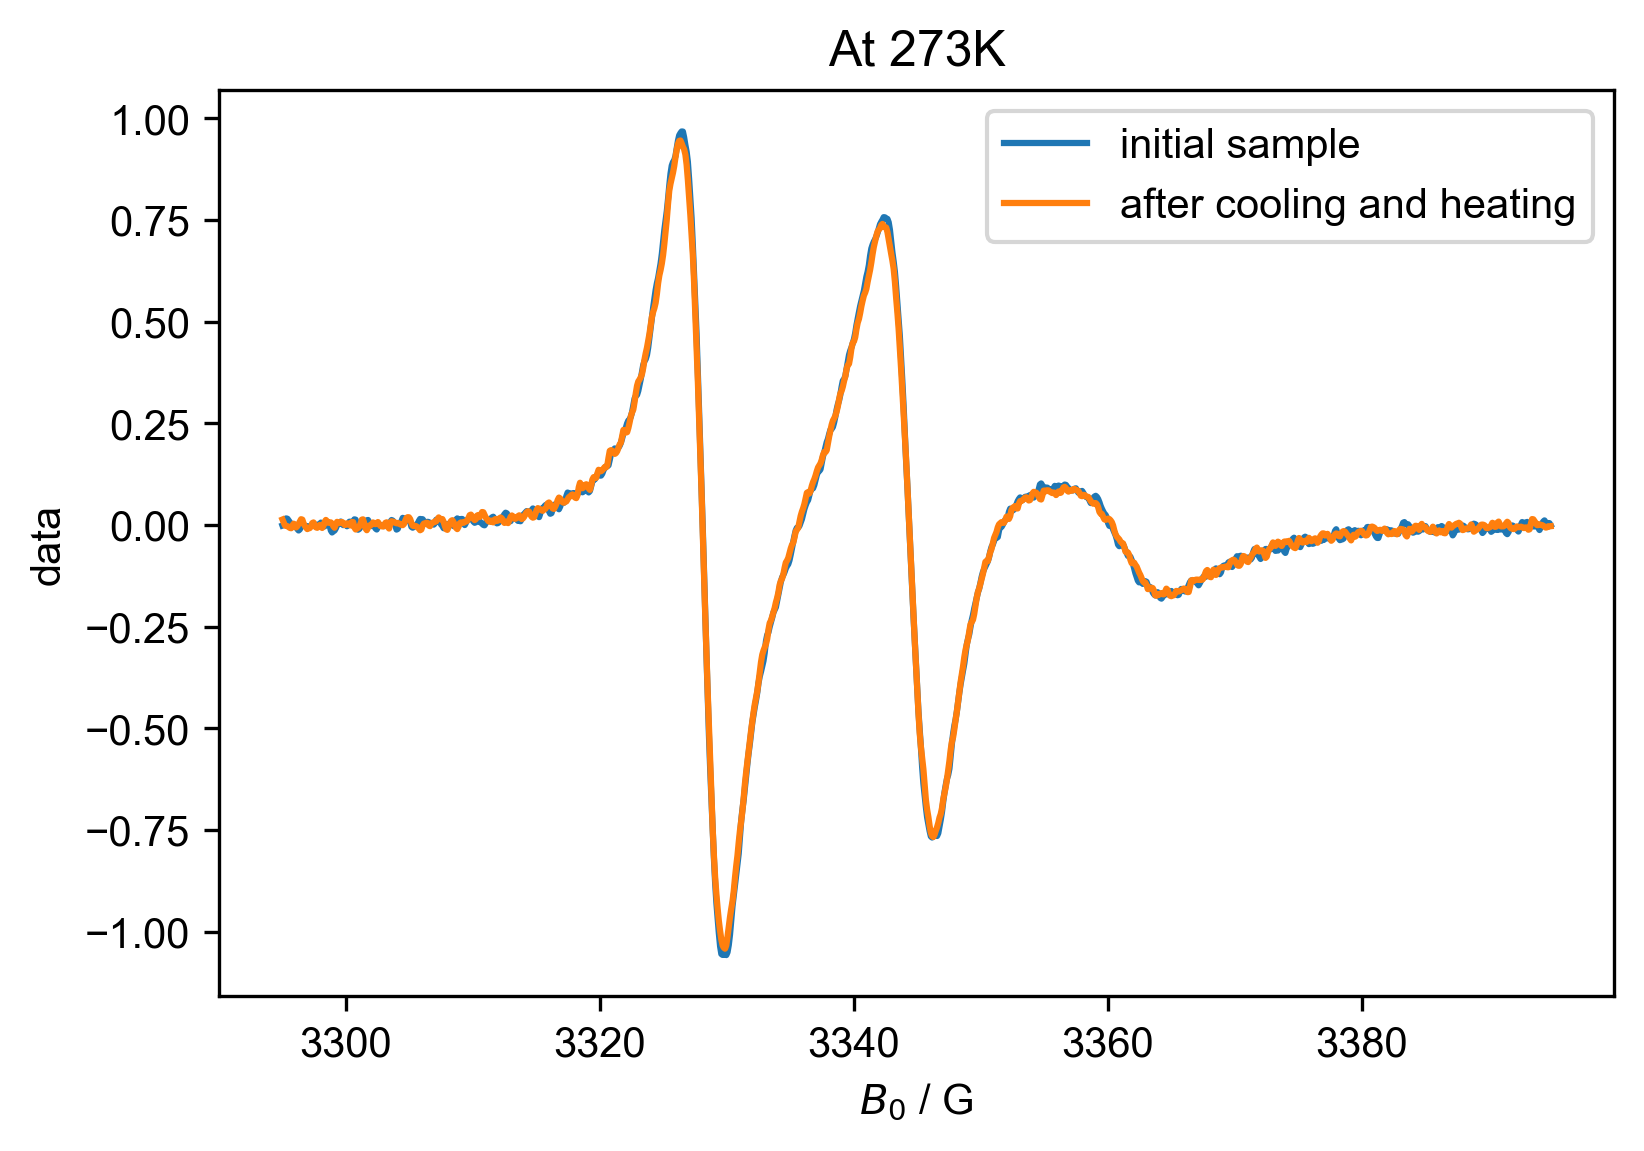

In [14]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":273], label="initial sample")
plot(d2["Temperature":273], label="after cooling and heating")
title("At 273K")
legend()

[252.878 253.46  255.296 256.403 257.35  258.125 259.201 260.302 261.178
 262.249 263.319 263.892 264.477 266.502 266.554 268.454 269.382 269.716
 271.077 272.036 272.38  274.273 274.514 276.382 276.56  277.284 279.417
 279.557 280.496 282.145 282.932]
[253.169 253.367 254.557 255.77  256.653 257.797 258.926 259.555 261.466
 261.649 263.358 264.295 264.373 266.372 267.33  268.351 269.253 270.294
 271.269 272.393 273.397 274.489 275.2   276.28  276.445 277.423 279.29
 280.242 281.372 282.183 283.527]


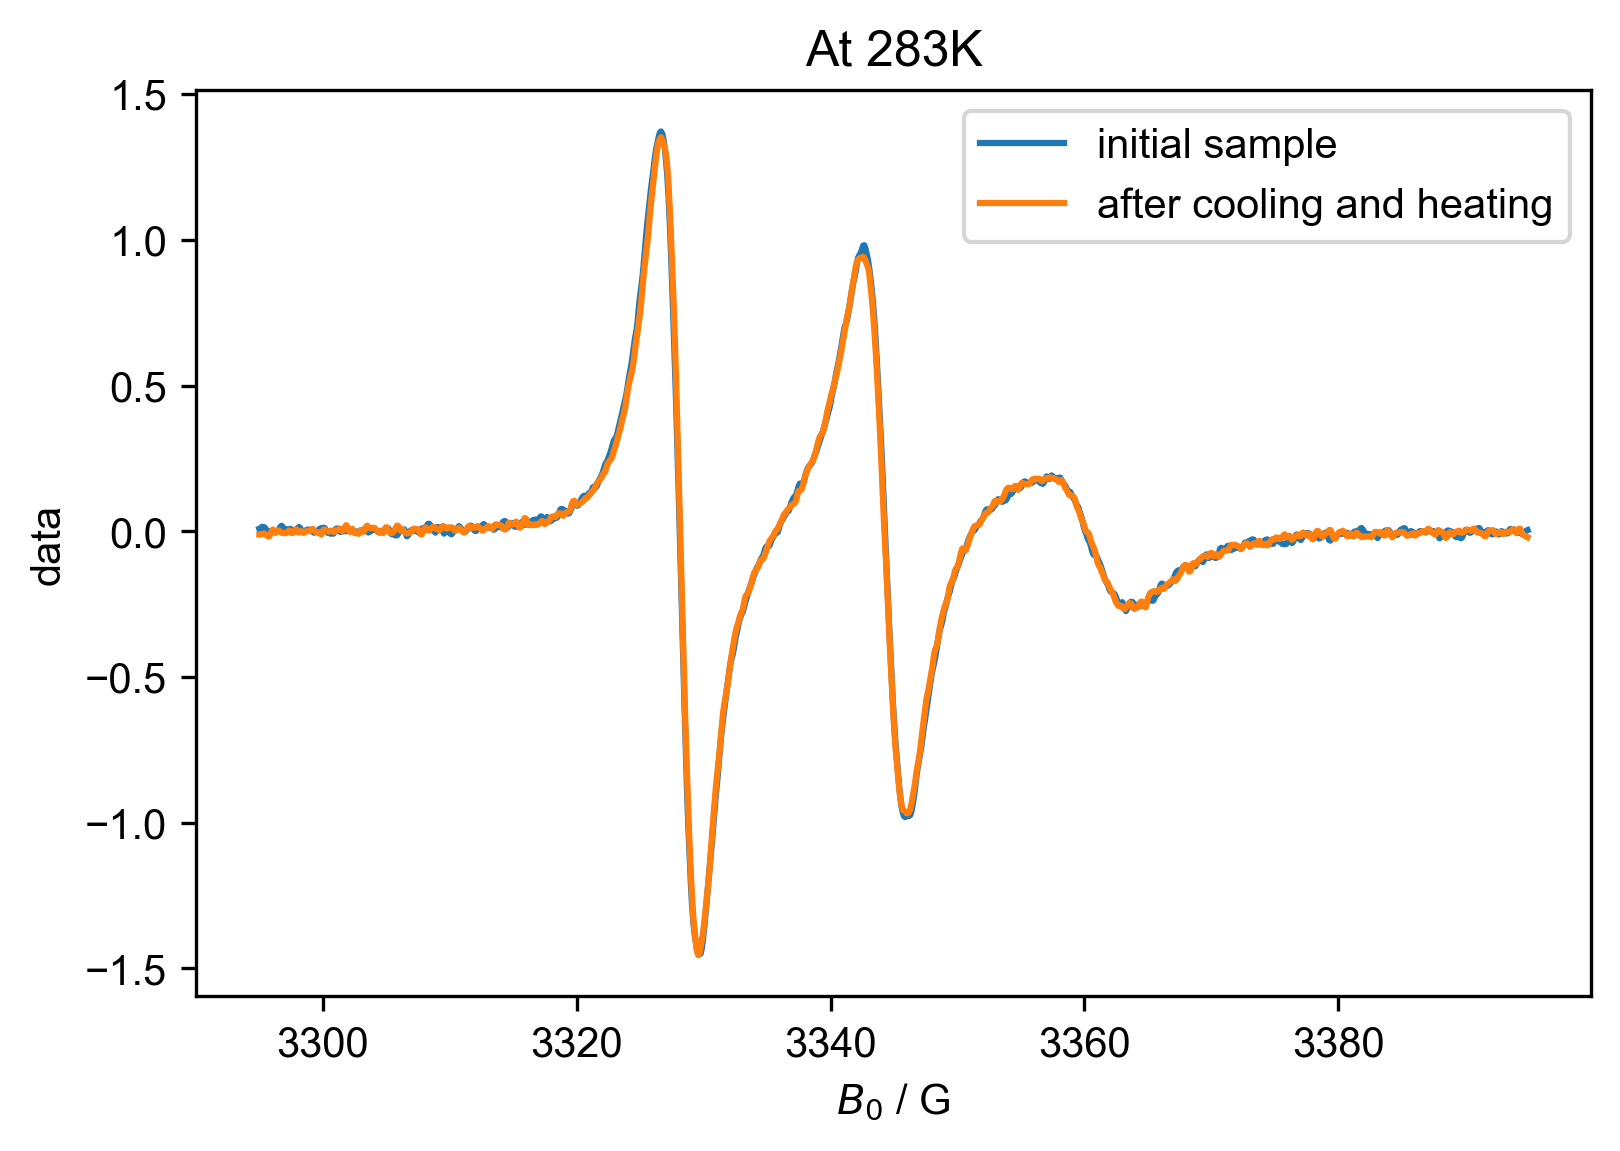

In [15]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":283], label="initial sample")
plot(d2["Temperature":283], label="after cooling and heating")
title("At 283K")
legend()

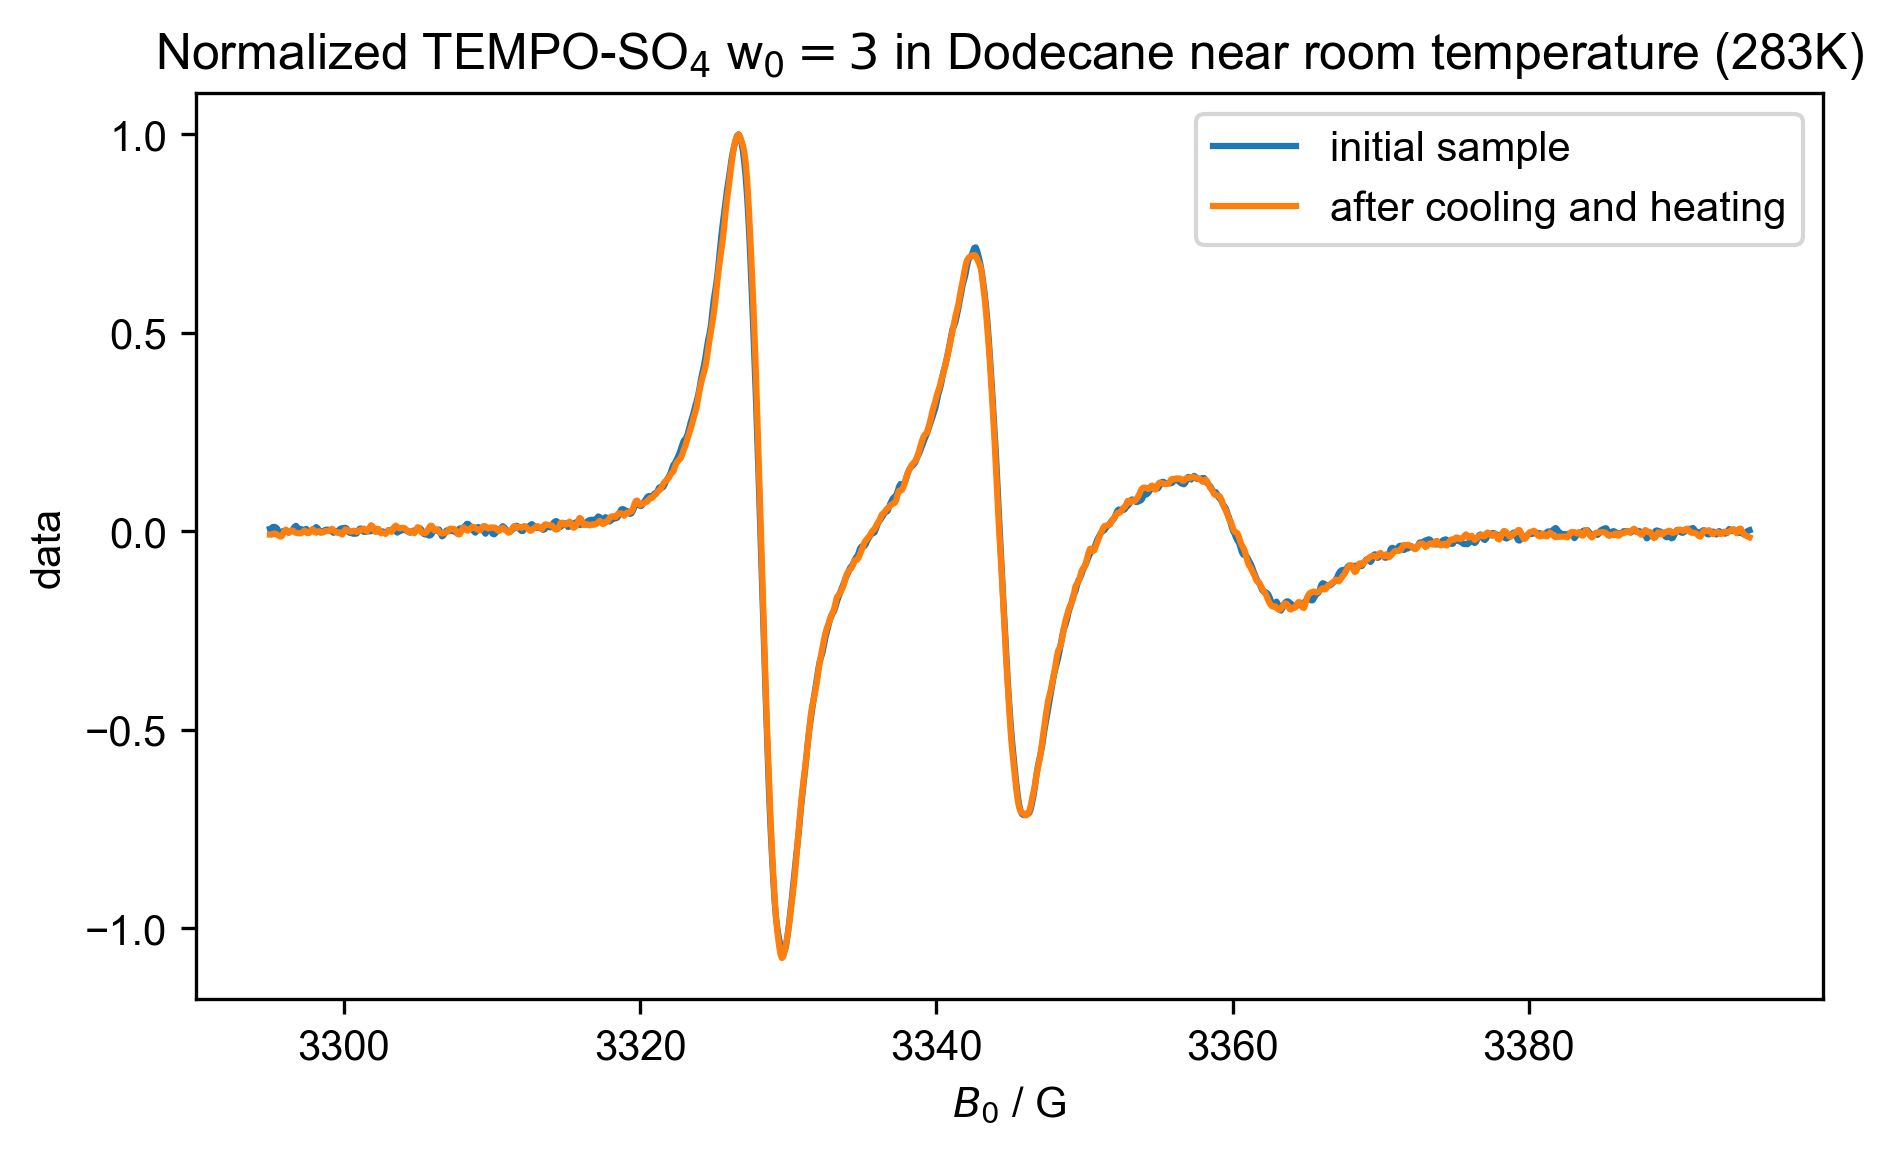

In [16]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "initial sample")
plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label= "after cooling and heating")
title("Normalized TEMPO-SO$_4$ w$_0= 3$ in Dodecane near room temperature (283K)")
legend()